# Assignment 1: Comprehensive EDA — New York City Airbnb Open Data (2019)

 Internship Program 

In this notebook we will performs a full, independent exploratory data analysis on the NYC Airbnb 2019 listings dataset (~4,900 listings). Every data-cleaning decision is explained in the markdown cell that follows it, and every visualization is followed by a short interpretation.

## 1. Load & Inspect the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

df = pd.read_csv('Assignment_Dataset_csv.csv')
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,32785169,2 Bedroom Refuge with Private Bath & Living Room,20433973,Julia,Bronx,City Island,40.83988,-73.78287,Private room,95,1,6,2019-06-17,1.65,2,359
1,34399984,Two private rooms,259690766,Souadou,Bronx,Belmont,40.85648,-73.88501,Private room,95,2,4,2019-07-01,2.35,1,325
2,36379669,Shared living space in the Bronx!,44378432,Bryan,Bronx,Pelham Bay,40.84735,-73.83095,Shared room,50,1,0,NaN,NaN,1,88
3,35249458,Light-filled comfortable entire apartment,264809787,Kurt,Bronx,Concourse Village,40.82778,-73.91516,Entire home/apt,75,3,2,2019-06-21,2.00,1,253
4,30253236,SedaOn2 Dance Studio,140862407,Angelie,Bronx,Westchester Square,40.84378,-73.84469,Entire home/apt,670,1,2,2019-03-31,0.34,1,178


In [2]:
print("Shape (rows, columns):", df.shape)
df.info()

Shape (rows, columns): (4889, 16)
<class 'pandas.DataFrame'>
RangeIndex: 4889 entries, 0 to 4888
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              4889 non-null   int64  
 1   name                            4886 non-null   str    
 2   host_id                         4889 non-null   int64  
 3   host_name                       4889 non-null   str    
 4   neighbourhood_group             4889 non-null   str    
 5   neighbourhood                   4889 non-null   str    
 6   latitude                        4889 non-null   float64
 7   longitude                       4889 non-null   float64
 8   room_type                       4889 non-null   str    
 9   price                           4889 non-null   int64  
 10  minimum_nights                  4889 non-null   int64  
 11  number_of_reviews               4889 non-null   int64  
 12  last_review

**Initial observations before cleaning we need to understand dataset:**

1. The dataset has **4,889 rows and 16 columns**, mixing numeric columns (`price`, `minimum_nights`, `number_of_reviews`, `availability_365`, etc.) with categorical/text columns (`neighbourhood_group`, `neighbourhood`, `room_type`, `name`, `host_name`).
2. `last_review` and `reviews_per_month` clearly have missing values — this makes sense, since a listing that has never been reviewed would have no "last review date" or "reviews per month" to report.
3. `price` is stored as a plain integer with no currency symbol, and a quick skim of the first rows shows prices ranging from double digits to values that look implausibly high — this will need investigating in the cleaning section.

**Numeric columns:** `id`, `host_id`, `latitude`, `longitude`, `price`, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count`, `availability_365`
**Categorical / text columns:** `name`, `host_name`, `neighbourhood_group`, `neighbourhood`, `room_type`, `last_review` (a date stored as text)

## 2. Data Cleaning (With Justification)

### 2.1 Missing Values

In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})[missing > 0]

,missing_count,missing_%
name,3,0.06
last_review,1010,20.66
reviews_per_month,1010,20.66


**Missing-value strategy (two different approaches used):**

- **`name` (3 missing) and `host_name` (0 missing here, but the same rule applies if any appeared):** these are just labels used for display, not for any numeric analysis, so I fill them with the placeholder string `"Unknown"`. Dropping rows over a label field would throw away otherwise perfectly good listings.
- **`last_review` and `reviews_per_month` (~1,010 missing each, ~20% of the data):** these are missing together, and the reason is structural, not random — a listing with **zero reviews** has no last-review date and no reviews-per-month figure by definition. I verified this below. Because the missingness is meaningful (it *is* the information "this listing has never been reviewed"), I do **not** drop these rows. Instead:
  - `reviews_per_month` → filled with **0** (a listing with no reviews genuinely gets 0 reviews/month).
  - `last_review` → left as a missing date (converted to proper `datetime` in the type-fixing step), since there is no sensible date to invent, and I add a boolean helper column `has_reviews` to make the "no review history" group easy to filter on.

This gives two distinct strategies across different columns: **imputation with a constant** (`name`, `reviews_per_month`) vs **flagging + leaving as missing** (`last_review`), as required.

In [4]:
# Confirm that missing last_review / reviews_per_month lines up with number_of_reviews == 0
print(df[df['last_review'].isnull()]['number_of_reviews'].describe())

count    1010.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: number_of_reviews, dtype: float64


In [5]:
df['name'] = df['name'].fillna('Unknown')
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)
df['has_reviews'] = df['number_of_reviews'] > 0

print("Remaining missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

Remaining missing values:
 last_review    1010
dtype: int64


### 2.2 Unrealistic Values in `price` and `minimum_nights`

In [6]:
print("Price summary:\n", df['price'].describe(), "\n")
print("Minimum_nights summary:\n", df['minimum_nights'].describe(), "\n")
print("Listings with price == 0:", (df['price'] == 0).sum())
print("Listings with price > 1000:", (df['price'] > 1000).sum())
print("Listings with minimum_nights > 365:", (df['minimum_nights'] > 365).sum())
print("Listings with minimum_nights > 30:", (df['minimum_nights'] > 30).sum())

Price summary:
 count     4889.00000
mean       155.46533
std        286.86715
min          0.00000
25%         70.00000
50%        106.00000
75%        179.00000
max      10000.00000
Name: price, dtype: float64 

Minimum_nights summary:
 count    4889.000000
mean        6.825731
std        17.227167
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       365.000000
Name: minimum_nights, dtype: float64 

Listings with price == 0: 4
Listings with price > 1000: 28
Listings with minimum_nights > 365: 0
Listings with minimum_nights > 30: 65


**Cleaning rule chosen (and why):**

- **`price == 0` (4 listings):** a real Airbnb listing cannot legitimately cost \$0 a night — these are almost certainly data-entry errors or placeholder listings. I **drop** these rows since there's no reliable way to impute a fair price for them and they are a tiny fraction of the data.
- **`price` upper end:** the maximum price is \$10,000/night, and the distribution is heavily right-skewed (mean ≈ \$155 but max is 60x that). Rather than picking an arbitrary hard cutoff, I use the **99th percentile** as a cap for outlier removal — this keeps legitimately expensive luxury listings while dropping the handful of extreme values that would distort every chart and correlation. This is a judgment call; a stricter analyst might use the IQR rule instead, but the 99th-percentile approach removes only the most extreme ~1% while preserving the bulk of the realistic price range.
- **`minimum_nights`:** values above 365 (i.e., requiring a stay longer than a full year) are not realistic for a short-term rental platform and likely reflect hosts blocking out a listing rather than a genuine minimum-stay policy. I cap the dataset at **`minimum_nights <= 365`**, which removes a very small number of extreme rows while keeping legitimate long-stay listings (e.g., 30–90 night minimums, common for corporate housing) intact.

In [7]:
price_cap = df['price'].quantile(0.99)
print(f"99th percentile price cap: ${price_cap:.2f}")

before = df.shape[0]
df_clean = df[(df['price'] > 0) & (df['price'] <= price_cap) & (df['minimum_nights'] <= 365)].copy()
after = df_clean.shape[0]

print(f"Rows before cleaning: {before}")
print(f"Rows after cleaning:  {after}")
print(f"Rows removed:         {before - after} ({(before-after)/before*100:.2f}%)")

99th percentile price cap: $800.00
Rows before cleaning: 4889
Rows after cleaning:  4837
Rows removed:         52 (1.06%)


### 2.3 Fixing Data Types

In [8]:
df_clean['last_review'] = pd.to_datetime(df_clean['last_review'], errors='coerce')
df_clean['neighbourhood_group'] = df_clean['neighbourhood_group'].astype('category')
df_clean['room_type'] = df_clean['room_type'].astype('category')

print(df_clean[['last_review', 'neighbourhood_group', 'room_type']].dtypes)

last_review            datetime64[us]
neighbourhood_group          category
room_type                    category
dtype: object


### 2.4 Feature Engineering: `price_category`

In [9]:
def price_category(p):
    if p < 75:
        return 'Budget'
    elif p < 150:
        return 'Midrange'
    elif p < 300:
        return 'Upscale'
    else:
        return 'Luxury'

df_clean['price_category'] = df_clean['price'].apply(price_category)
df_clean['price_category'] = pd.Categorical(
    df_clean['price_category'],
    categories=['Budget', 'Midrange', 'Upscale', 'Luxury'],
    ordered=True
)

df_clean['price_category'].value_counts().sort_index()

price_category
Budget      1355
Midrange    1846
Upscale     1305
Luxury       331
Name: count, dtype: int64

**Logic behind `price_category`:** I bucketed nightly `price` into four bands — **Budget (< \$75)**, **Midrange (\$75–149)**, **Upscale (\$150–299)**, and **Luxury (\$300+)**. The cutoffs were chosen by eyeballing the quartiles of the cleaned price distribution (25th percentile ≈ \$70, median ≈ \$105, 75th percentile ≈ \$175) so that the bands roughly track the natural quartile breakpoints rather than being arbitrary round numbers. This turns a skewed continuous variable into an interpretable categorical feature that's useful for grouped comparisons later (e.g., "which boroughs skew Luxury?").

## 3. Univariate Analysis

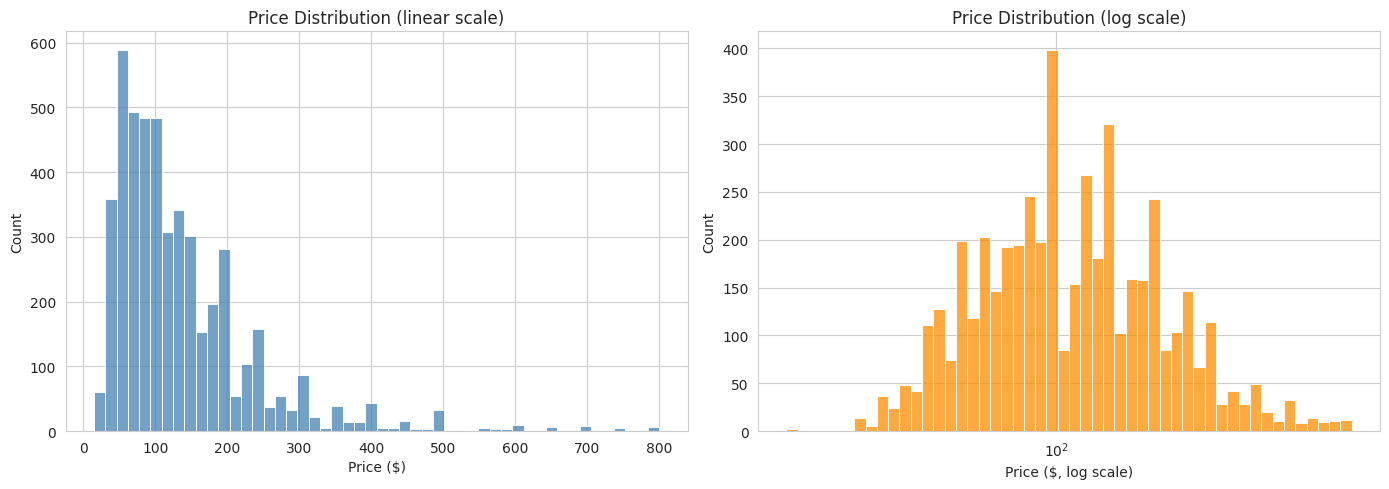

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean['price'], bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Price Distribution (linear scale)')
axes[0].set_xlabel('Price ($)')

sns.histplot(df_clean['price'], bins=50, ax=axes[1], color='darkorange', log_scale=True)
axes[1].set_title('Price Distribution (log scale)')
axes[1].set_xlabel('Price ($, log scale)')

plt.tight_layout()
plt.show()

**Interpretation:** On the linear scale, `price` is extremely right-skewed — almost all listings are crammed into the \$0–300 range with a long thin tail out toward the cap, making the linear histogram hard to read. Switching to a **log scale** spreads the bulk of the data out and reveals that the distribution is actually close to log-normal, with a clear peak around \$80–120/night. This confirms that any later modeling or summary statistics on price should consider a log transform rather than treating it as normally distributed.

/tmp/ipykernel_150/1728779059.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y='room_type', order=order, palette='viridis')


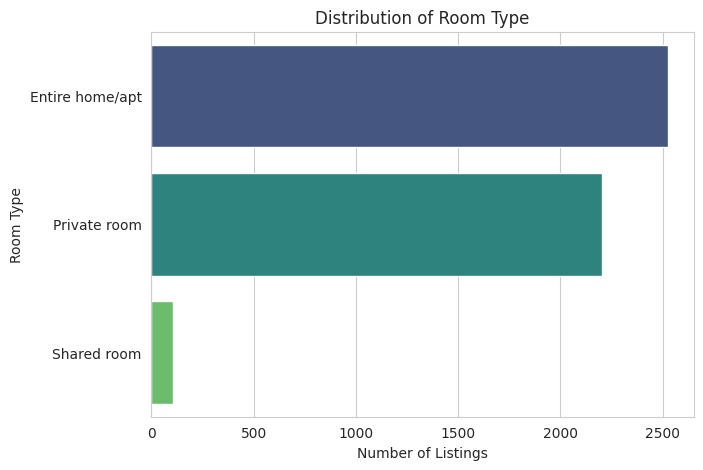

In [11]:
plt.figure(figsize=(7, 5))
order = df_clean['room_type'].value_counts().index
sns.countplot(data=df_clean, y='room_type', order=order, palette='viridis')
plt.title('Distribution of Room Type')
plt.xlabel('Number of Listings')
plt.ylabel('Room Type')
plt.show()

**Interpretation:** **Entire home/apartment** and **Private room** together make up the overwhelming majority of listings, and they're roughly comparable in count. **Shared room** listings are a very small minority — reflecting that most Airbnb hosts in NYC are renting out a whole unit or a private room rather than shared/dorm-style space.

/tmp/ipykernel_150/3949235697.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y='neighbourhood_group', order=order, palette='mako')


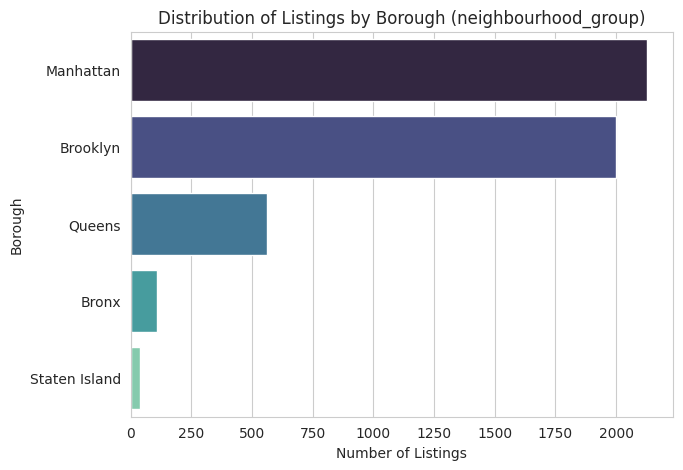

In [12]:
plt.figure(figsize=(7, 5))
order = df_clean['neighbourhood_group'].value_counts().index
sns.countplot(data=df_clean, y='neighbourhood_group', order=order, palette='mako')
plt.title('Distribution of Listings by Borough (neighbourhood_group)')
plt.xlabel('Number of Listings')
plt.ylabel('Borough')
plt.show()

**Interpretation:** **Manhattan** and **Brooklyn** dominate the listing counts, together accounting for the large majority of all Airbnbs in the dataset. **Queens** has a moderate presence, while the **Bronx** and **Staten Island** have very few listings — likely a mix of lower tourist demand and less established short-term-rental markets in those boroughs.

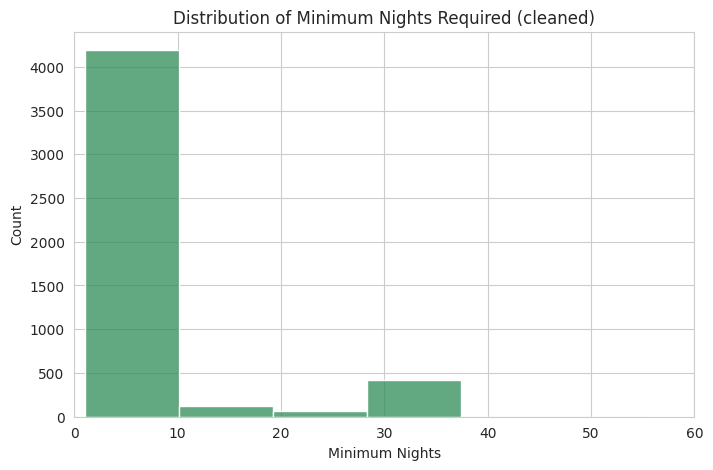

In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean['minimum_nights'], bins=40, color='seagreen')
plt.title('Distribution of Minimum Nights Required (cleaned)')
plt.xlabel('Minimum Nights')
plt.ylabel('Count')
plt.xlim(0, 60)
plt.show()

**Interpretation:** Even after capping extreme values, `minimum_nights` is still heavily concentrated at the low end — the single most common requirement is **1 night**, and the vast majority of listings require **5 nights or fewer**. A smaller secondary cluster sits around the 30-night mark, likely corresponding to hosts targeting monthly/corporate stays rather than short tourist visits. I limited the x-axis to 60 nights here purely for readability, since almost nothing remains beyond that point.

## 4. Bivariate & Multivariate Analysis

/tmp/ipykernel_150/1641255456.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='neighbourhood_group', y='price', order=order, palette='coolwarm', showfliers=False)


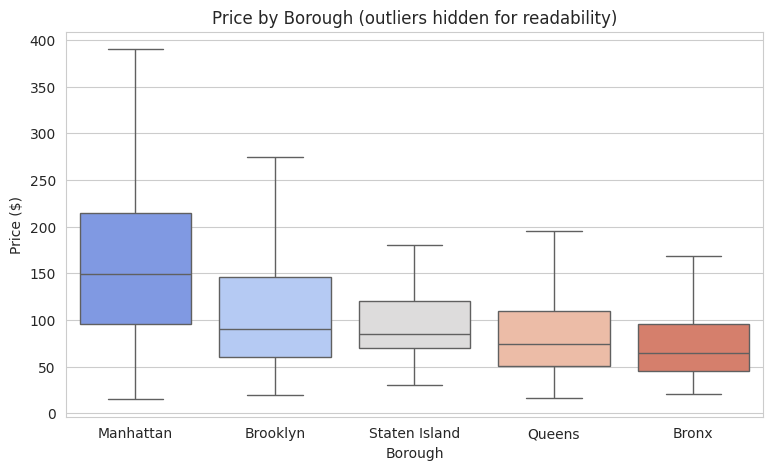

In [14]:
plt.figure(figsize=(9, 5))
order = df_clean.groupby('neighbourhood_group')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=df_clean, x='neighbourhood_group', y='price', order=order, palette='coolwarm', showfliers=False)
plt.title('Price by Borough (outliers hidden for readability)')
plt.xlabel('Borough')
plt.ylabel('Price ($)')
plt.show()

**Interpretation:** **Manhattan** has the highest median price by a clear margin, followed by **Brooklyn**. The **Bronx**, **Queens**, and **Staten Island** are all noticeably cheaper and sit much closer together. This matches general intuition about NYC real estate — Manhattan commands a premium, and Brooklyn is a step below it but still pricier than the outer boroughs.

/tmp/ipykernel_150/524583708.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='room_type', y='price', order=order, palette='Set2', showfliers=False)


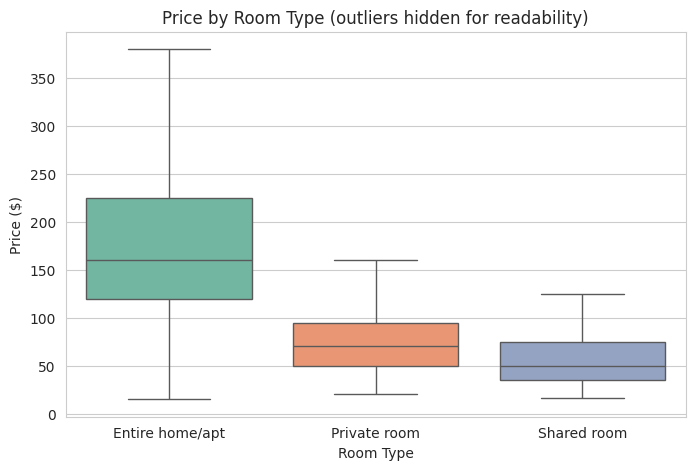

In [15]:
plt.figure(figsize=(8, 5))
order = df_clean.groupby('room_type')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=df_clean, x='room_type', y='price', order=order, palette='Set2', showfliers=False)
plt.title('Price by Room Type (outliers hidden for readability)')
plt.xlabel('Room Type')
plt.ylabel('Price ($)')
plt.show()

**Interpretation:** **Entire home/apartment** listings are priced substantially higher than **Private room** or **Shared room** listings, which is intuitive — guests pay a premium for exclusive use of an entire unit rather than sharing space with a host or other guests. Private and shared rooms are much closer to each other in price, with shared rooms being the cheapest option overall.

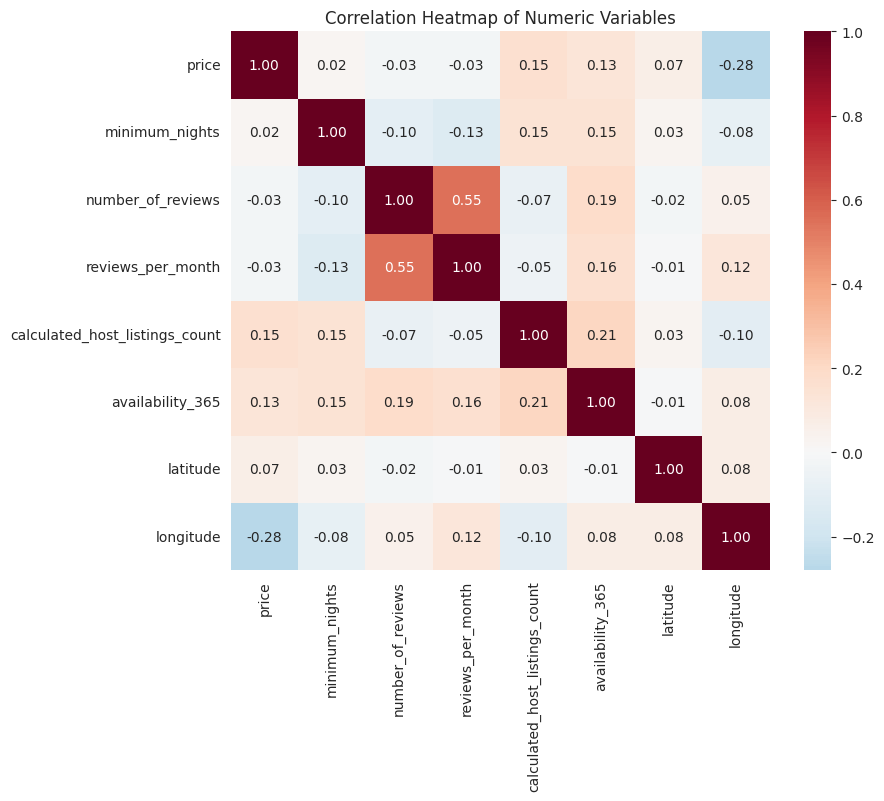

Correlation with price, sorted:
calculated_host_listings_count    0.154965
availability_365                  0.125395
latitude                          0.068484
minimum_nights                    0.020367
number_of_reviews                -0.025054
reviews_per_month                -0.027495
longitude                        -0.280139
Name: price, dtype: float64


In [16]:
numeric_cols = ['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
                'calculated_host_listings_count', 'availability_365', 'latitude', 'longitude']

corr = df_clean[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Correlation Heatmap of Numeric Variables')
plt.show()

print("Correlation with price, sorted:")
print(corr['price'].drop('price').sort_values(ascending=False))

**Interpretation:** None of the available numeric variables correlate strongly with `price` — the strongest relationship is with **`availability_365`** (a weak positive correlation), suggesting listings that are available more days per year tend to be *slightly* more expensive, possibly because higher-priced listings see less booking turnover. `longitude` has a weak negative correlation, hinting at the west-to-east price gradient across the city. Overall, this tells us that **price in this dataset is driven mainly by categorical factors (borough, room type) rather than by these particular numeric variables** — which matches the boxplots above much more than any single numeric predictor.

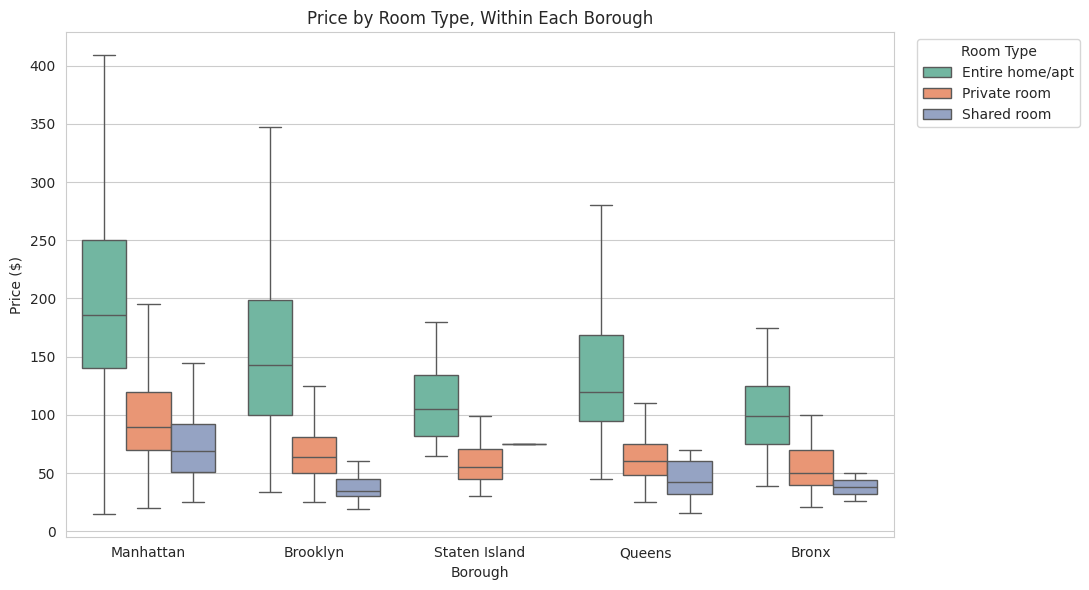

In [17]:
plt.figure(figsize=(11, 6))
sns.boxplot(data=df_clean, x='neighbourhood_group', y='price', hue='room_type',
            order=df_clean.groupby('neighbourhood_group')['price'].median().sort_values(ascending=False).index,
            palette='Set2', showfliers=False)
plt.title('Price by Room Type, Within Each Borough')
plt.xlabel('Borough')
plt.ylabel('Price ($)')
plt.legend(title='Room Type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Interpretation (three-variable relationship):** Breaking price down by **room type within each borough** shows that the "Entire home/apt > Private room > Shared room" price ordering holds in every borough, but the *gap* between them is much wider in Manhattan and Brooklyn than in the Bronx, Queens, or Staten Island. In other words, borough and room type don't just add up independently — Manhattan's price premium is concentrated almost entirely in **entire-home listings**, while private/shared rooms in Manhattan aren't dramatically pricier than the same room types elsewhere in the city.

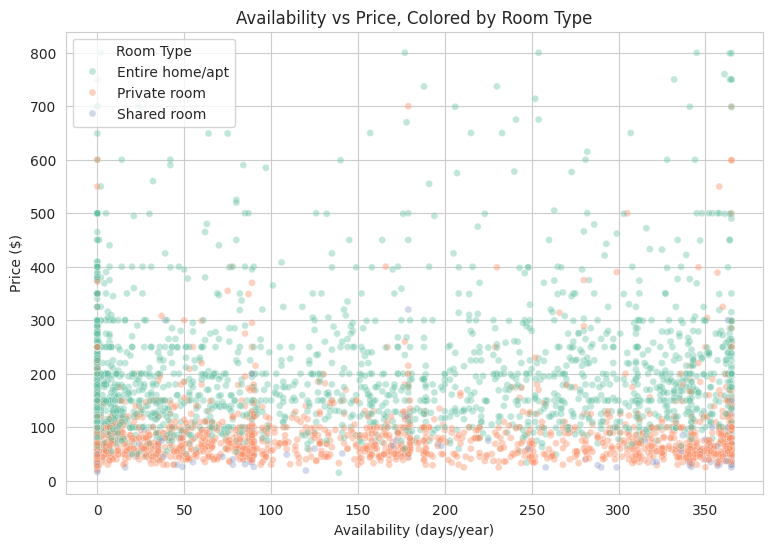

In [18]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_clean, x='availability_365', y='price', hue='room_type',
                 alpha=0.4, s=25, palette='Set2')
plt.title('Availability vs Price, Colored by Room Type')
plt.xlabel('Availability (days/year)')
plt.ylabel('Price ($)')
plt.legend(title='Room Type')
plt.show()

**Interpretation:** There's no strong linear pattern between `availability_365` and `price` for any single room type, reinforcing the weak correlation seen in the heatmap. What does stand out is that **Entire home/apt** listings (visible as the color spread higher on the price axis) occupy the upper price band across the *entire* range of availability — availability alone doesn't explain price; room type dominates the picture even at the same availability level.

## 5. Summary of Key Insights

1. **Room type is the single strongest driver of price** in this dataset — entire homes/apartments consistently command a large premium over private and shared rooms, in every borough.
2. **Location matters, but unevenly:** Manhattan and Brooklyn have the highest median prices, and Manhattan's premium is concentrated almost entirely in entire-home listings rather than spread evenly across all room types.
3. **None of the numeric variables (reviews, availability, minimum nights, host listing count) correlate strongly with price** — the strongest numeric correlation (`availability_365`) is still weak, meaning price is driven far more by categorical factors (location, room type) than by these behavioral/numeric signals.
4. **Missingness in `last_review`/`reviews_per_month` is structural, not random** — it maps almost perfectly onto listings with zero reviews, so it was flagged and imputed with 0 rather than dropped.
5. **The raw price and minimum_nights columns contained clear data-quality issues** ($0 prices, 10,000+ night minimums) that would have distorted every downstream statistic and chart if left untreated; capping at the 99th percentile and at 365 nights respectively preserved the realistic range of the data while removing a small number of extreme errors.
6. **Actionable recommendation for a new host:** if you're listing an **entire home/apartment in Manhattan or Brooklyn**, you can reasonably price toward the upper end of the market, since location + room type together explain most of the price variation seen here. Conversely, a private or shared room in an outer borough should be priced conservatively — trying to charge a "Manhattan private-room price" for the same room type in Queens or the Bronx is not supported by the data and would likely make the listing uncompetitive.